In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

/Users/sagarrudagi/Desktop/Learning/Coding - Projects/NLP Learning/lcm/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [3]:
class QuadState(TypedDict):
    a: int
    b: int
    c: int

    equation: str
    discriminant: float
    result: str

In [4]:
def show_equation(state: QuadState):
    eq = f"{state['a']}x^2 + {state['b']}x + {state['c']} = 0"
    return {"equation": eq}

In [5]:
def calculate_discriminant(state: QuadState):
    a = state['a']
    b = state['b']
    c = state['c']
    discriminant = b**2 - 4*a*c
    return {"discriminant": discriminant}

In [15]:
def real_roots(state: QuadState):
    a = state['a']
    b = state['b']
    discriminant = state['discriminant']
    root1 = (-b + discriminant**0.5) / (2*a)
    root2 = (-b - discriminant**0.5) / (2*a)
    return {"result": f"Real roots: {root1}, {root2}"}

In [14]:
def repeated_roots(state: QuadState):
    a = state['a']
    b = state['b']
    root = -b / (2*a)
    return {"result": f"Repeated root: {root}"}

In [13]:
def nonreal_roots(state: QuadState):
    a = state['a']
    b = state['b']
    discriminant = state['discriminant']
    real_part = -b / (2*a)
    imaginary_part = (abs(discriminant)**0.5) / (2*a)
    return {"result": f"No real roots: {real_part} ± {imaginary_part}i"}

In [24]:
def check_condition(state: QuadState) -> Literal["real_roots", "repeated_roots", "nonreal_roots"]:
    discriminant = state['discriminant']
    if discriminant > 0:
        return "real_roots"
    elif discriminant == 0:
        return "repeated_roots"
    else:
        return "nonreal_roots"

In [25]:
graph = StateGraph(QuadState)

graph.add_node("show_equation", show_equation)
graph.add_node("calculate_discriminant", calculate_discriminant)
graph.add_node("real_roots", real_roots)
graph.add_node("repeated_roots", repeated_roots)
graph.add_node("nonreal_roots", nonreal_roots)

graph.add_edge(START, "show_equation")
graph.add_edge("show_equation", "calculate_discriminant")
graph.add_conditional_edges("calculate_discriminant", check_condition)
graph.add_edge("real_roots", END)
graph.add_edge("repeated_roots", END)
graph.add_edge("nonreal_roots", END)

workflow = graph.compile()

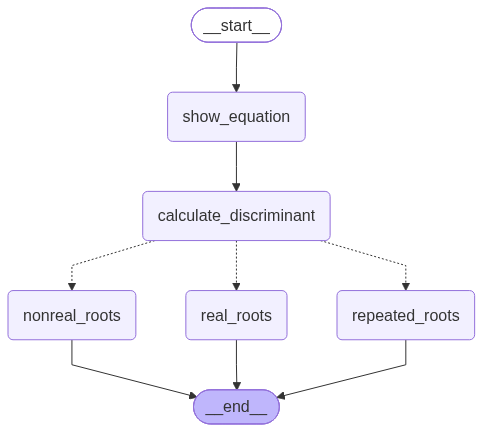

In [26]:
workflow

In [28]:
initial_state = {
    'a': 2, 
    'b': 4,
    'c': 2
}

workflow.invoke(initial_state)

{'a': 2,
 'b': 4,
 'c': 2,
 'equation': '2x^2 + 4x + 2 = 0',
 'discriminant': 0,
 'result': 'Repeated root: -1.0'}